# Matched 823-Patient Early vs Late Multimodal Fusion

This notebook reruns the fusion study using **exactly the same 823 complete-case patients for every experiment**.

The purpose is to make all comparisons directly comparable:

- Clinical only
- RNA-Seq only
- DNA methylation only
- WSI only
- Omics = RNA-Seq + methylation
- Clinical + Omics
- Full = Clinical + RNA-Seq + methylation + WSI
- Leave-one-modality-out ablations

Two feature-budget settings are evaluated:

1. **Original**
   - Clinical: 44 selected features
   - RNA-Seq: 100 selected genes
   - DNA methylation: 100 selected CpGs
   - WSI: 100 split-safe PCA components

2. **Equal40**
   - 40 features/components per modality

The notebook **does not retrain ABMIL**. It uses the split-safe WSI feature files already produced by `07_controlled_early_late_fusion.ipynb`.

The held-out train/test assignment is preserved from `train_test_split.csv`.

## 1. Imports and configuration

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.base import clone
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")

# Project paths
import os

BASE_DIR = Path(
    os.environ.get("FUSION_REPO_DIR", str(Path.cwd()))
).expanduser().resolve()

if BASE_DIR.name in {"Preprocessing", "Training"}:
    BASE_DIR = BASE_DIR.parent

if not (BASE_DIR / "Training" / "07_controlled_early_late_fusion.ipynb").is_file():
    raise RuntimeError(
        "Start Jupyter from the repository directory or set FUSION_REPO_DIR."
    )
DATA_DIR = Path(
    os.environ.get("FUSION_DATA_DIR", str(BASE_DIR / "Data"))
).expanduser().resolve()
ANALYSIS_DIR = BASE_DIR
PREP_DIR = ANALYSIS_DIR / "Preprocessing"

LABELS_PATH = DATA_DIR / "multiomics_labels.tsv"
SPLIT_PATH = DATA_DIR / "train_test_split.csv"

CONTROL_DIR = ANALYSIS_DIR / "Controlled-Fusion"
FEATURE_DIR = CONTROL_DIR / "Features"

MATCHED_DIR = ANALYSIS_DIR / "Matched-823-Fusion"
RESULT_DIR = MATCHED_DIR / "Results"
FIG_DIR = MATCHED_DIR / "Figures"

for d in [MATCHED_DIR, RESULT_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Original preprocessing outputs
CLINICAL_ORIGINAL_PATH = PREP_DIR / "clinical_features.csv"
RNA_ORIGINAL_PATH = PREP_DIR / "rna_selected_features.csv"
METH_ORIGINAL_PATH = PREP_DIR / "methylation_selected_features.csv"

# Split-safe WSI outputs from notebook 07
WSI_ORIGINAL_PATH = FEATURE_DIR / "wsi_features_split_safe_100.csv"
WSI_EQUAL40_PATH = FEATURE_DIR / "wsi_features_split_safe_40.csv"

# Equal40 outputs from notebook 07
CLINICAL_EQUAL40_PATH = FEATURE_DIR / "clinical_features_fusion40.csv"
RNA_EQUAL40_PATH = FEATURE_DIR / "rna_features_fusion40.csv"
METH_EQUAL40_PATH = FEATURE_DIR / "methylation_features_fusion40.csv"

RANDOM_STATE = 42
CV_FOLDS = 10
N_JOBS = -1

print("Matched 823-patient fusion configuration loaded.")
print(f"Results will be saved to: {RESULT_DIR}")

Matched 823-patient fusion configuration loaded.
Results will be saved to: /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/Multimodal-Analysis/Matched-823-Fusion/Results


## 2. Load labels and the authoritative train/test split

Patient IDs are normalized to the 12-character TCGA participant identifier.

The existing train/test assignment is preserved. No new random outer split is created.

In [2]:
def normalize_id(x):
    return str(x).strip().upper()[:12]


labels_df = pd.read_csv(LABELS_PATH, sep="\t")

if "patient_id" not in labels_df.columns:
    raise ValueError("multiomics_labels.tsv must contain a 'patient_id' column.")

labels_df["patient_id"] = labels_df["patient_id"].map(normalize_id)

if "subtype_simple" not in labels_df.columns:
    raise ValueError("multiomics_labels.tsv must contain a 'subtype_simple' column.")

labels = (
    labels_df
    .drop_duplicates("patient_id")
    .set_index("patient_id")["subtype_simple"]
    .astype(str)
    .str.strip()
    .map({"LUAD": 0, "LUSC": 1})
    .dropna()
    .astype(int)
)


# Train/test split
split_df = pd.read_csv(SPLIT_PATH)

if "patient_id" not in split_df.columns:
    split_df = pd.read_csv(SPLIT_PATH, index_col=0).reset_index()
    split_df = split_df.rename(columns={split_df.columns[0]: "patient_id"})

split_df["patient_id"] = split_df["patient_id"].map(normalize_id)
split_df = split_df.drop_duplicates("patient_id").set_index("patient_id")

if "split" not in split_df.columns:
    raise ValueError("train_test_split.csv must contain a 'split' column.")

split_df["split"] = split_df["split"].astype(str).str.lower().str.strip()

print(f"Labels available : {len(labels)}")
print(f"Split entries    : {len(split_df)}")
print("\nSplit labels:")
print(split_df["split"].value_counts())

Labels available : 831
Split entries    : 831

Split labels:
split
train    581
test     250
Name: count, dtype: int64


## 3. Load all modality feature matrices

Both Original and Equal40 representations are loaded before the cohort is defined.

This is important: the **master 823-patient cohort is defined once**, using the intersection across all required modalities, and is then reused unchanged for every experiment.

In [3]:
def load_feature_csv(path, name):
    if not path.exists():
        raise FileNotFoundError(
            f"{name} file not found:\n{path}\n\n"
            "Run 07_controlled_early_late_fusion.ipynb first if this is a split-safe WSI or Equal40 file."
        )

    df = pd.read_csv(path, index_col=0)
    df.index = [normalize_id(i) for i in df.index]
    df = df[~df.index.duplicated(keep="first")]

    # Force numeric values
    df = df.apply(pd.to_numeric, errors="coerce")

    if df.isna().any().any():
        n_missing = int(df.isna().sum().sum())
        raise ValueError(f"{name} contains {n_missing} missing/non-numeric values.")

    return df


clinical_original = load_feature_csv(
    CLINICAL_ORIGINAL_PATH, "Original Clinical"
)
rna_original = load_feature_csv(
    RNA_ORIGINAL_PATH, "Original RNA-Seq"
)
meth_original = load_feature_csv(
    METH_ORIGINAL_PATH, "Original Methylation"
)
wsi_original = load_feature_csv(
    WSI_ORIGINAL_PATH, "Original split-safe WSI"
)

clinical_equal40 = load_feature_csv(
    CLINICAL_EQUAL40_PATH, "Equal40 Clinical"
)
rna_equal40 = load_feature_csv(
    RNA_EQUAL40_PATH, "Equal40 RNA-Seq"
)
meth_equal40 = load_feature_csv(
    METH_EQUAL40_PATH, "Equal40 Methylation"
)
wsi_equal40 = load_feature_csv(
    WSI_EQUAL40_PATH, "Equal40 split-safe WSI"
)

print("Original feature matrices")
print(f"  Clinical       : {clinical_original.shape}")
print(f"  RNA-Seq        : {rna_original.shape}")
print(f"  Methylation    : {meth_original.shape}")
print(f"  WSI            : {wsi_original.shape}")

print("\nEqual40 feature matrices")
print(f"  Clinical       : {clinical_equal40.shape}")
print(f"  RNA-Seq        : {rna_equal40.shape}")
print(f"  Methylation    : {meth_equal40.shape}")
print(f"  WSI            : {wsi_equal40.shape}")

Original feature matrices
  Clinical       : (831, 44)
  RNA-Seq        : (825, 100)
  Methylation    : (826, 100)
  WSI            : (823, 100)

Equal40 feature matrices
  Clinical       : (831, 40)
  RNA-Seq        : (825, 40)
  Methylation    : (826, 40)
  WSI            : (823, 40)


## 4. Define the single master complete-case cohort

This is the key correction.

Previously, some experiments used 825 patients while the Full four-modality experiment used 823. Here, a patient must have:

- a valid LUAD/LUSC label,
- an existing train/test assignment,
- Clinical features,
- RNA-Seq features,
- methylation features,
- split-safe WSI features.

The resulting patient set is then used for **every** model.

In [4]:
# Intersect ORIGINAL representations.
# Equal40 matrices are derived from these same modality datasets, but
# we also verify their coverage below.
master_set = (
    set(labels.index)
    & set(split_df.index)
    & set(clinical_original.index)
    & set(rna_original.index)
    & set(meth_original.index)
    & set(wsi_original.index)
    & set(clinical_equal40.index)
    & set(rna_equal40.index)
    & set(meth_equal40.index)
    & set(wsi_equal40.index)
)

# Preserve original split-file order
MASTER_IDS = [
    pid for pid in split_df.index
    if pid in master_set
]

MASTER_TRAIN_IDS = [
    pid for pid in MASTER_IDS
    if split_df.loc[pid, "split"] == "train"
]

MASTER_TEST_IDS = [
    pid for pid in MASTER_IDS
    if split_df.loc[pid, "split"] == "test"
]

print("MASTER COMPLETE-CASE COHORT")
print(f"Total patients : {len(MASTER_IDS)}")
print(f"Train patients : {len(MASTER_TRAIN_IDS)}")
print(f"Test patients  : {len(MASTER_TEST_IDS)}")

print("\nTrain class distribution:")
print(
    labels.loc[MASTER_TRAIN_IDS]
    .value_counts()
    .sort_index()
    .rename(index={0: "LUAD", 1: "LUSC"})
)

print("\nTest class distribution:")
print(
    labels.loc[MASTER_TEST_IDS]
    .value_counts()
    .sort_index()
    .rename(index={0: "LUAD", 1: "LUSC"})
)

if len(MASTER_IDS) != 823:
    raise RuntimeError(
        f"Expected 823 complete-case patients, but found {len(MASTER_IDS)}. "
        "Do not continue until the discrepancy is understood."
    )

print("\nConfirmed: every experiment will use the same 823 patients.")

MASTER COMPLETE-CASE COHORT
Total patients : 823
Train patients : 578
Test patients  : 245

Train class distribution:
subtype_simple
LUAD    319
LUSC    259
Name: count, dtype: int64

Test class distribution:
subtype_simple
LUAD    135
LUSC    110
Name: count, dtype: int64

Confirmed: every experiment will use the same 823 patients.


## 5. Restrict every modality to the same 823 patients

After this cell, there is no modality-specific patient intersection.

Every representation has exactly the same row order:

\[
	exttt{MASTER\_IDS}
\]

This prevents RNA-only, Omics, or Clinical+Omics experiments from silently using additional patients.

In [5]:
ORIGINAL = {
    "Clinical": clinical_original.loc[MASTER_IDS].copy(),
    "RNA-Seq": rna_original.loc[MASTER_IDS].copy(),
    "Methylation": meth_original.loc[MASTER_IDS].copy(),
    "WSI": wsi_original.loc[MASTER_IDS].copy(),
}

EQUAL40 = {
    "Clinical": clinical_equal40.loc[MASTER_IDS].copy(),
    "RNA-Seq": rna_equal40.loc[MASTER_IDS].copy(),
    "Methylation": meth_equal40.loc[MASTER_IDS].copy(),
    "WSI": wsi_equal40.loc[MASTER_IDS].copy(),
}

FEATURE_SETS = {
    "Original": ORIGINAL,
    "Equal40": EQUAL40,
}

for budget_name, modality_dict in FEATURE_SETS.items():
    print(f"\n{budget_name}")
    for modality, df in modality_dict.items():
        print(f"  {modality:<15}: {df.shape}")

        assert list(df.index) == MASTER_IDS
        assert len(df) == 823

print("\nAll eight matrices use exactly the same 823 patients in the same order.")


Original
  Clinical       : (823, 44)
  RNA-Seq        : (823, 100)
  Methylation    : (823, 100)
  WSI            : (823, 100)

Equal40
  Clinical       : (823, 40)
  RNA-Seq        : (823, 40)
  Methylation    : (823, 40)
  WSI            : (823, 40)

All eight matrices use exactly the same 823 patients in the same order.


## 6. Save the matched cohort manifest

This file documents exactly which patients were used and their train/test assignment.

It is useful for reproducibility and for the manuscript methods section.

In [6]:
cohort_manifest = pd.DataFrame({
    "patient_id": MASTER_IDS,
    "split": [split_df.loc[pid, "split"] for pid in MASTER_IDS],
    "label_numeric": [labels.loc[pid] for pid in MASTER_IDS],
    "subtype": [
        "LUAD" if labels.loc[pid] == 0 else "LUSC"
        for pid in MASTER_IDS
    ],
})

COHORT_PATH = RESULT_DIR / "matched_823_cohort_manifest.csv"
cohort_manifest.to_csv(COHORT_PATH, index=False)

print(f"Saved: {COHORT_PATH}")
display(cohort_manifest.head())

Saved: /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/Multimodal-Analysis/Matched-823-Fusion/Results/matched_823_cohort_manifest.csv


,patient_id,split,label_numeric,subtype
0,TCGA-86-8056,train,0,LUAD
1,TCGA-97-A4M6,train,0,LUAD
2,TCGA-33-6737,train,1,LUSC
3,TCGA-60-2709,train,1,LUSC
4,TCGA-J2-8194,train,0,LUAD


## 7. Define classifiers

The same six classical classifiers are retained so that the rerun remains comparable with the previous experiment.

In [7]:
CLASSIFIERS = {
    "LDA": LinearDiscriminantAnalysis(),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "CART": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "NB": GaussianNB(),
    "SVM": SVC(
        kernel="rbf",
        C=1.0,
        probability=True,
        random_state=RANDOM_STATE,
    ),
    "LR": LogisticRegression(
        solver="saga",
        C=1.0,
        max_iter=2000,
        random_state=RANDOM_STATE,
    ),
}

print("Classifiers:", list(CLASSIFIERS.keys()))

Classifiers: ['LDA', 'KNN', 'CART', 'NB', 'SVM', 'LR']


## 8. Define modality combinations

The same matched 823 patients are used even when a model uses only one modality.

The incremental RNA combinations are included explicitly because RNA-Seq is the strongest unimodal signal and we want to quantify what each additional modality contributes.

In [8]:
UNIMODAL_COMBINATIONS = {
    "Unimodal-Clinical": ["Clinical"],
    "Unimodal-RNA-Seq": ["RNA-Seq"],
    "Unimodal-Methylation": ["Methylation"],
    "Unimodal-WSI": ["WSI"],
}

INCREMENTAL_RNA_COMBINATIONS = {
    "RNA+Clinical": ["RNA-Seq", "Clinical"],
    "RNA+Methylation": ["RNA-Seq", "Methylation"],
    "RNA+WSI": ["RNA-Seq", "WSI"],
}

CORE_COMBINATIONS = {
    "Omics": ["RNA-Seq", "Methylation"],
    "Clinical+Omics": ["Clinical", "RNA-Seq", "Methylation"],
    "Full": ["Clinical", "RNA-Seq", "Methylation", "WSI"],
}

ABLATION_COMBINATIONS = {
    "Full-no-Clinical": ["RNA-Seq", "Methylation", "WSI"],
    "Full-no-RNA": ["Clinical", "Methylation", "WSI"],
    "Full-no-Methylation": ["Clinical", "RNA-Seq", "WSI"],
    "Full-no-WSI": ["Clinical", "RNA-Seq", "Methylation"],
}

EARLY_COMBINATIONS = {
    **UNIMODAL_COMBINATIONS,
    **INCREMENTAL_RNA_COMBINATIONS,
    **CORE_COMBINATIONS,
    **ABLATION_COMBINATIONS,
}

# Late fusion is only meaningful for 2+ modalities
LATE_COMBINATIONS = {
    **INCREMENTAL_RNA_COMBINATIONS,
    **CORE_COMBINATIONS,
    **ABLATION_COMBINATIONS,
}

FUSION_RULES = ["Maximum", "Sum", "Product"]

print(f"Early combinations: {len(EARLY_COMBINATIONS)}")
print(f"Late combinations : {len(LATE_COMBINATIONS)}")

Early combinations: 14
Late combinations : 10


## 9. Fixed train/test masks for all experiments

These masks are created once and reused everywhere.

In [9]:
MASTER_Y = labels.loc[MASTER_IDS].values

TRAIN_MASK = np.array([
    split_df.loc[pid, "split"] == "train"
    for pid in MASTER_IDS
])

TEST_MASK = np.array([
    split_df.loc[pid, "split"] == "test"
    for pid in MASTER_IDS
])

Y_TRAIN = MASTER_Y[TRAIN_MASK]
Y_TEST = MASTER_Y[TEST_MASK]

print(f"Training samples: {TRAIN_MASK.sum()}")
print(f"Test samples    : {TEST_MASK.sum()}")

assert TRAIN_MASK.sum() == len(MASTER_TRAIN_IDS)
assert TEST_MASK.sum() == len(MASTER_TEST_IDS)
assert TRAIN_MASK.sum() + TEST_MASK.sum() == 823

Training samples: 578
Test samples    : 245


## 10. Evaluation metrics and training-only threshold selection

The held-out test set is not used for threshold selection.

Thresholds are selected using out-of-fold training probabilities and then frozen for final test evaluation.

In [10]:
def make_cv():
    return StratifiedKFold(
        n_splits=CV_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE,
    )


def compute_binary_metrics(y_true, y_prob, threshold=0.5):
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)
    y_pred = (y_prob >= threshold).astype(int)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    sensitivity = tp / (tp + fn) if (tp + fn) else np.nan
    specificity = tn / (tn + fp) if (tn + fp) else np.nan

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
        "auc_roc": roc_auc_score(y_true, y_prob),
        "sensitivity": sensitivity,
        "specificity": specificity,
    }


def choose_threshold(y_true, y_prob):
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    candidates = np.unique(
        np.concatenate([
            np.linspace(0.05, 0.95, 181),
            np.quantile(y_prob, np.linspace(0.02, 0.98, 99)),
            np.array([0.5]),
        ])
    )

    best_threshold = 0.5
    best_f1 = -np.inf
    best_accuracy = -np.inf

    for threshold in candidates:
        pred = (y_prob >= threshold).astype(int)
        current_f1 = f1_score(y_true, pred, average="macro")
        current_accuracy = accuracy_score(y_true, pred)

        if (
            current_f1 > best_f1 + 1e-12
            or (
                abs(current_f1 - best_f1) <= 1e-12
                and current_accuracy > best_accuracy
            )
        ):
            best_threshold = float(threshold)
            best_f1 = current_f1
            best_accuracy = current_accuracy

    return best_threshold


def fuse_probabilities(probability_list, rule):
    probs = np.column_stack(probability_list)
    probs = np.clip(probs, 1e-8, 1 - 1e-8)

    if rule == "Maximum":
        return probs.max(axis=1)

    if rule == "Sum":
        return probs.sum(axis=1)

    if rule == "Product":
        return probs.prod(axis=1)

    raise ValueError(f"Unknown fusion rule: {rule}")

## 11. Build matched early-fusion matrices

No patient intersection occurs inside this function.

Every matrix is built directly from the same `MASTER_IDS`.

In [11]:
def build_early_matrix(modality_dict, modalities):
    blocks = []

    for modality in modalities:
        block = modality_dict[modality].loc[MASTER_IDS].copy()
        block.columns = [
            f"{modality}__{column}"
            for column in block.columns
        ]
        blocks.append(block)

    X_df = pd.concat(blocks, axis=1)

    assert len(X_df) == 823
    assert list(X_df.index) == MASTER_IDS

    return X_df

## 12. Evaluate early feature-level fusion

In [12]:
def evaluate_early_fusion(
    budget_name,
    modality_dict,
    combination_name,
    combination_modalities,
):
    X_df = build_early_matrix(
        modality_dict,
        combination_modalities,
    )

    X = X_df.values
    X_train = X[TRAIN_MASK]
    X_test = X[TEST_MASK]

    rows = []

    print(
        f"\n[{budget_name}] {combination_name}: "
        f"823 patients, {X_df.shape[1]} features"
    )

    for classifier_name, estimator in CLASSIFIERS.items():
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("clf", clone(estimator)),
        ])

        # Training-only OOF predictions
        oof_prob = cross_val_predict(
            model,
            X_train,
            Y_TRAIN,
            cv=make_cv(),
            method="predict_proba",
            n_jobs=N_JOBS,
        )[:, 1]

        threshold = choose_threshold(
            Y_TRAIN,
            oof_prob,
        )

        oof_metrics = compute_binary_metrics(
            Y_TRAIN,
            oof_prob,
            threshold,
        )

        # Final test evaluation
        model.fit(X_train, Y_TRAIN)
        test_prob = model.predict_proba(X_test)[:, 1]

        test_metrics = compute_binary_metrics(
            Y_TEST,
            test_prob,
            threshold,
        )

        rows.append({
            "budget": budget_name,
            "strategy": "Early",
            "combination": combination_name,
            "modalities": "+".join(combination_modalities),
            "n_patients": 823,
            "n_features": X_df.shape[1],
            "n_train": int(TRAIN_MASK.sum()),
            "n_test": int(TEST_MASK.sum()),
            "classifier": classifier_name,
            "fusion_rule": "",
            "threshold": threshold,
            "oof_accuracy": oof_metrics["accuracy"],
            "oof_f1_macro": oof_metrics["f1_macro"],
            "oof_auc_roc": oof_metrics["auc_roc"],
            "oof_sensitivity": oof_metrics["sensitivity"],
            "oof_specificity": oof_metrics["specificity"],
            "test_accuracy": test_metrics["accuracy"],
            "test_f1_macro": test_metrics["f1_macro"],
            "test_auc_roc": test_metrics["auc_roc"],
            "test_sensitivity": test_metrics["sensitivity"],
            "test_specificity": test_metrics["specificity"],
        })

        print(
            f"  {classifier_name:<5} "
            f"OOF AUC={oof_metrics['auc_roc']:.4f} | "
            f"Test AUC={test_metrics['auc_roc']:.4f} | "
            f"Test Acc={test_metrics['accuracy']:.4f}"
        )

    return pd.DataFrame(rows)

## 13. Evaluate late decision-level fusion

Each modality receives an independent model of the same classifier family.

There is no test-set normalization. Fusion thresholds are selected from fused out-of-fold **training** predictions only.

In [13]:
def evaluate_late_fusion(
    budget_name,
    modality_dict,
    combination_name,
    combination_modalities,
):
    rows = []

    print(
        f"\n[{budget_name}] {combination_name}: "
        f"823 patients, {len(combination_modalities)} modalities"
    )

    for classifier_name, estimator in CLASSIFIERS.items():
        oof_probabilities = []
        test_probabilities = []

        for modality in combination_modalities:
            X = modality_dict[modality].loc[MASTER_IDS].values

            X_train = X[TRAIN_MASK]
            X_test = X[TEST_MASK]

            model = Pipeline([
                ("scaler", StandardScaler()),
                ("clf", clone(estimator)),
            ])

            oof_prob = cross_val_predict(
                model,
                X_train,
                Y_TRAIN,
                cv=make_cv(),
                method="predict_proba",
                n_jobs=N_JOBS,
            )[:, 1]

            model.fit(X_train, Y_TRAIN)
            test_prob = model.predict_proba(X_test)[:, 1]

            oof_probabilities.append(oof_prob)
            test_probabilities.append(test_prob)

        for rule in FUSION_RULES:
            fused_oof = fuse_probabilities(
                oof_probabilities,
                rule,
            )

            threshold = choose_threshold(
                Y_TRAIN,
                fused_oof,
            )

            oof_metrics = compute_binary_metrics(
                Y_TRAIN,
                fused_oof,
                threshold,
            )

            fused_test = fuse_probabilities(
                test_probabilities,
                rule,
            )

            test_metrics = compute_binary_metrics(
                Y_TEST,
                fused_test,
                threshold,
            )

            rows.append({
                "budget": budget_name,
                "strategy": "Late",
                "combination": combination_name,
                "modalities": "+".join(combination_modalities),
                "n_patients": 823,
                "n_features": sum(
                    modality_dict[m].shape[1]
                    for m in combination_modalities
                ),
                "n_train": int(TRAIN_MASK.sum()),
                "n_test": int(TEST_MASK.sum()),
                "classifier": classifier_name,
                "fusion_rule": rule,
                "threshold": threshold,
                "oof_accuracy": oof_metrics["accuracy"],
                "oof_f1_macro": oof_metrics["f1_macro"],
                "oof_auc_roc": oof_metrics["auc_roc"],
                "oof_sensitivity": oof_metrics["sensitivity"],
                "oof_specificity": oof_metrics["specificity"],
                "test_accuracy": test_metrics["accuracy"],
                "test_f1_macro": test_metrics["f1_macro"],
                "test_auc_roc": test_metrics["auc_roc"],
                "test_sensitivity": test_metrics["sensitivity"],
                "test_specificity": test_metrics["specificity"],
            })

        print(f"  Completed {classifier_name}")

    return pd.DataFrame(rows)

# Run the matched experiments

## 14. Run all early-fusion and unimodal experiments

In [14]:
early_frames = []

for budget_name, modality_dict in FEATURE_SETS.items():
    print(f"EARLY FUSION / UNIMODAL - {budget_name}")

    for combination_name, modalities in EARLY_COMBINATIONS.items():
        result = evaluate_early_fusion(
            budget_name,
            modality_dict,
            combination_name,
            modalities,
        )
        early_frames.append(result)

early_results = pd.concat(
    early_frames,
    ignore_index=True,
)

EARLY_PATH = RESULT_DIR / "early_fusion_matched_823.csv"
early_results.to_csv(EARLY_PATH, index=False)

print(f"\nSaved: {EARLY_PATH}")
print(f"Rows: {len(early_results)}")

assert early_results["n_patients"].eq(823).all()

EARLY FUSION / UNIMODAL - Original

[Original] Unimodal-Clinical: 823 patients, 44 features
  LDA   OOF AUC=0.7240 | Test AUC=0.6844 | Test Acc=0.6531
  KNN   OOF AUC=0.6566 | Test AUC=0.6254 | Test Acc=0.6082
  CART  OOF AUC=0.5885 | Test AUC=0.6069 | Test Acc=0.6122
  NB    OOF AUC=0.6903 | Test AUC=0.6838 | Test Acc=0.6694
  SVM   OOF AUC=0.7406 | Test AUC=0.6891 | Test Acc=0.6408
  LR    OOF AUC=0.7316 | Test AUC=0.6933 | Test Acc=0.6449

[Original] Unimodal-RNA-Seq: 823 patients, 100 features
  LDA   OOF AUC=0.9860 | Test AUC=0.9989 | Test Acc=0.9755
  KNN   OOF AUC=0.9691 | Test AUC=0.9936 | Test Acc=0.9755
  CART  OOF AUC=0.9042 | Test AUC=0.9311 | Test Acc=0.9306
  NB    OOF AUC=0.9746 | Test AUC=0.9951 | Test Acc=0.9796
  SVM   OOF AUC=0.9818 | Test AUC=0.9983 | Test Acc=0.9796
  LR    OOF AUC=0.9846 | Test AUC=0.9952 | Test Acc=0.9592

[Original] Unimodal-Methylation: 823 patients, 100 features
  LDA   OOF AUC=0.9615 | Test AUC=0.9932 | Test Acc=0.9592
  KNN   OOF AUC=0.9561 

## 15. Run all late-fusion experiments

In [15]:
late_frames = []

for budget_name, modality_dict in FEATURE_SETS.items():
    print(f"LATE FUSION — {budget_name}")

    for combination_name, modalities in LATE_COMBINATIONS.items():
        result = evaluate_late_fusion(
            budget_name,
            modality_dict,
            combination_name,
            modalities,
        )
        late_frames.append(result)

late_results = pd.concat(
    late_frames,
    ignore_index=True,
)

LATE_PATH = RESULT_DIR / "late_fusion_matched_823.csv"
late_results.to_csv(LATE_PATH, index=False)

print(f"\nSaved: {LATE_PATH}")
print(f"Rows: {len(late_results)}")

assert late_results["n_patients"].eq(823).all()

LATE FUSION — Original

[Original] RNA+Clinical: 823 patients, 2 modalities
  Completed LDA
  Completed KNN
  Completed CART
  Completed NB
  Completed SVM
  Completed LR

[Original] RNA+Methylation: 823 patients, 2 modalities
  Completed LDA
  Completed KNN
  Completed CART
  Completed NB
  Completed SVM
  Completed LR

[Original] RNA+WSI: 823 patients, 2 modalities
  Completed LDA
  Completed KNN
  Completed CART
  Completed NB
  Completed SVM
  Completed LR

[Original] Omics: 823 patients, 2 modalities
  Completed LDA
  Completed KNN
  Completed CART
  Completed NB
  Completed SVM
  Completed LR

[Original] Clinical+Omics: 823 patients, 3 modalities
  Completed LDA
  Completed KNN
  Completed CART
  Completed NB
  Completed SVM
  Completed LR

[Original] Full: 823 patients, 4 modalities
  Completed LDA
  Completed KNN
  Completed CART
  Completed NB
  Completed SVM
  Completed LR

[Original] Full-no-Clinical: 823 patients, 3 modalities
  Completed LDA
  Completed KNN
  Completed CAR

## 16. Select the best configuration using training OOF AUC

The test set is not used to choose the winning classifier or late-fusion rule.

In [16]:
def select_best_by_oof(df):
    return (
        df.sort_values(
            ["budget", "combination", "oof_auc_roc", "oof_f1_macro"],
            ascending=[True, True, False, False],
        )
        .groupby(["budget", "combination"], as_index=False)
        .head(1)
        .reset_index(drop=True)
    )


best_early = select_best_by_oof(early_results)
best_late = select_best_by_oof(late_results)

BEST_EARLY_PATH = RESULT_DIR / "best_early_matched_823.csv"
BEST_LATE_PATH = RESULT_DIR / "best_late_matched_823.csv"

best_early.to_csv(BEST_EARLY_PATH, index=False)
best_late.to_csv(BEST_LATE_PATH, index=False)

print("Best early/unimodal models:")
display(
    best_early[
        [
            "budget",
            "combination",
            "classifier",
            "n_patients",
            "n_features",
            "test_accuracy",
            "test_auc_roc",
        ]
    ]
)

print("\nBest late-fusion models:")
display(
    best_late[
        [
            "budget",
            "combination",
            "classifier",
            "fusion_rule",
            "n_patients",
            "test_accuracy",
            "test_auc_roc",
        ]
    ]
)

Best early/unimodal models:


,budget,combination,classifier,n_patients,n_features,test_accuracy,test_auc_roc
0,Equal40,Clinical+Omics,SVM,823,120,0.967347,0.998451
1,Equal40,Full,LDA,823,160,0.963265,0.992795
2,Equal40,Full-no-Clinical,LDA,823,120,0.959184,0.992458
3,Equal40,Full-no-Methylation,LDA,823,120,0.955102,0.995286
4,Equal40,Full-no-RNA,LDA,823,120,0.963265,0.988081
5,Equal40,Full-no-WSI,SVM,823,120,0.967347,0.998451
6,Equal40,Omics,SVM,823,80,0.971429,0.998653
7,Equal40,RNA+Clinical,SVM,823,80,0.975510,0.998586
8,Equal40,RNA+Methylation,SVM,823,80,0.971429,0.998653
9,Equal40,RNA+WSI,LDA,823,80,0.959184,0.995219



Best late-fusion models:


,budget,combination,classifier,fusion_rule,n_patients,test_accuracy,test_auc_roc
0,Equal40,Clinical+Omics,LR,Sum,823,0.967347,0.997710
1,Equal40,Full,LR,Product,823,0.979592,0.993535
2,Equal40,Full-no-Clinical,LR,Sum,823,0.959184,0.998721
3,Equal40,Full-no-Methylation,LDA,Product,823,0.959184,0.989697
4,Equal40,Full-no-RNA,LR,Product,823,0.951020,0.985320
5,Equal40,Full-no-WSI,LR,Sum,823,0.967347,0.997710
6,Equal40,Omics,LR,Sum,823,0.971429,0.997508
7,Equal40,RNA+Clinical,SVM,Product,823,0.975510,0.988013
8,Equal40,RNA+Methylation,LR,Sum,823,0.971429,0.997508
9,Equal40,RNA+WSI,LR,Sum,823,0.971429,0.996902


## 17. Direct RNA-only versus multimodal comparison

This is the key table for the question:

> Does multimodal fusion add predictive value beyond RNA-Seq alone when all models are evaluated on the exact same 823 patients?

In [17]:
comparison_names = [
    "Unimodal-RNA-Seq",
    "RNA+Clinical",
    "RNA+Methylation",
    "RNA+WSI",
    "Omics",
    "Clinical+Omics",
    "Full",
]

rna_incremental_rows = []

for budget in FEATURE_SETS:
    early_budget = best_early[
        best_early["budget"] == budget
    ].set_index("combination")

    late_budget = best_late[
        best_late["budget"] == budget
    ].set_index("combination")

    rna_row = early_budget.loc["Unimodal-RNA-Seq"]

    baseline_acc = rna_row["test_accuracy"]
    baseline_auc = rna_row["test_auc_roc"]

    # RNA-only baseline
    rna_incremental_rows.append({
        "budget": budget,
        "strategy": "Unimodal",
        "combination": "RNA only",
        "classifier": rna_row["classifier"],
        "fusion_rule": "",
        "n_patients": 823,
        "test_accuracy": baseline_acc,
        "test_auc_roc": baseline_auc,
        "delta_accuracy_vs_RNA": 0.0,
        "delta_auc_vs_RNA": 0.0,
    })

    # Early multimodal
    for combination in comparison_names[1:]:
        if combination in early_budget.index:
            row = early_budget.loc[combination]

            rna_incremental_rows.append({
                "budget": budget,
                "strategy": "Early",
                "combination": combination,
                "classifier": row["classifier"],
                "fusion_rule": "",
                "n_patients": 823,
                "test_accuracy": row["test_accuracy"],
                "test_auc_roc": row["test_auc_roc"],
                "delta_accuracy_vs_RNA": row["test_accuracy"] - baseline_acc,
                "delta_auc_vs_RNA": row["test_auc_roc"] - baseline_auc,
            })

    # Late multimodal
    for combination in comparison_names[1:]:
        if combination in late_budget.index:
            row = late_budget.loc[combination]

            rna_incremental_rows.append({
                "budget": budget,
                "strategy": "Late",
                "combination": combination,
                "classifier": row["classifier"],
                "fusion_rule": row["fusion_rule"],
                "n_patients": 823,
                "test_accuracy": row["test_accuracy"],
                "test_auc_roc": row["test_auc_roc"],
                "delta_accuracy_vs_RNA": row["test_accuracy"] - baseline_acc,
                "delta_auc_vs_RNA": row["test_auc_roc"] - baseline_auc,
            })


rna_incremental = pd.DataFrame(rna_incremental_rows)

RNA_COMPARISON_PATH = RESULT_DIR / "rna_vs_multimodal_matched_823.csv"
rna_incremental.to_csv(RNA_COMPARISON_PATH, index=False)

display(rna_incremental)
print(f"\nSaved: {RNA_COMPARISON_PATH}")

,budget,strategy,combination,classifier,fusion_rule,n_patients,test_accuracy,test_auc_roc,delta_accuracy_vs_RNA,delta_auc_vs_RNA
0,Original,Unimodal,RNA only,LDA,,823,0.975510,0.998855,0.000000,0.000000
1,Original,Early,RNA+Clinical,LDA,,823,0.983673,0.998855,0.008163,0.000000
2,Original,Early,RNA+Methylation,SVM,,823,0.963265,0.998586,-0.012245,-0.000269
3,Original,Early,RNA+WSI,LDA,,823,0.963265,0.991919,-0.012245,-0.006936
4,Original,Early,Omics,SVM,,823,0.963265,0.998586,-0.012245,-0.000269
5,Original,Early,Clinical+Omics,SVM,,823,0.963265,0.998586,-0.012245,-0.000269
6,Original,Early,Full,SVM,,823,0.963265,0.998451,-0.012245,-0.000404
7,Original,Late,RNA+Clinical,LDA,Product,823,0.975510,0.993131,0.000000,-0.005724
8,Original,Late,RNA+Methylation,SVM,Product,823,0.971429,0.998384,-0.004082,-0.000471
9,Original,Late,RNA+WSI,LDA,Sum,823,0.963265,0.996633,-0.012245,-0.002222



Saved: /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/Multimodal-Analysis/Matched-823-Fusion/Results/rna_vs_multimodal_matched_823.csv


## 18. Matched early-vs-late comparison

This table compares early and late fusion for identical modality combinations using the same 823 patients.

In [18]:
matched_names = [
    "RNA+Clinical",
    "RNA+Methylation",
    "RNA+WSI",
    "Omics",
    "Clinical+Omics",
    "Full",
]

early_matched = best_early[
    best_early["combination"].isin(matched_names)
].copy()

late_matched = best_late[
    best_late["combination"].isin(matched_names)
].copy()

early_vs_late = early_matched.merge(
    late_matched,
    on=["budget", "combination"],
    suffixes=("_early", "_late"),
)

early_vs_late["delta_accuracy_late_minus_early"] = (
    early_vs_late["test_accuracy_late"]
    - early_vs_late["test_accuracy_early"]
)

early_vs_late["delta_auc_late_minus_early"] = (
    early_vs_late["test_auc_roc_late"]
    - early_vs_late["test_auc_roc_early"]
)

early_vs_late_summary = early_vs_late[
    [
        "budget",
        "combination",
        "classifier_early",
        "test_accuracy_early",
        "test_auc_roc_early",
        "classifier_late",
        "fusion_rule_late",
        "test_accuracy_late",
        "test_auc_roc_late",
        "delta_accuracy_late_minus_early",
        "delta_auc_late_minus_early",
    ]
].copy()

EARLY_LATE_PATH = RESULT_DIR / "early_vs_late_matched_823.csv"
early_vs_late_summary.to_csv(EARLY_LATE_PATH, index=False)

display(early_vs_late_summary)
print(f"\nSaved: {EARLY_LATE_PATH}")

,budget,combination,classifier_early,test_accuracy_early,test_auc_roc_early,classifier_late,fusion_rule_late,test_accuracy_late,test_auc_roc_late,delta_accuracy_late_minus_early,delta_auc_late_minus_early
0,Equal40,Clinical+Omics,SVM,0.967347,0.998451,LR,Sum,0.967347,0.997710,0.000000,-0.000741
1,Equal40,Full,LDA,0.963265,0.992795,LR,Product,0.979592,0.993535,0.016327,0.000741
2,Equal40,Omics,SVM,0.971429,0.998653,LR,Sum,0.971429,0.997508,0.000000,-0.001145
3,Equal40,RNA+Clinical,SVM,0.975510,0.998586,SVM,Product,0.975510,0.988013,0.000000,-0.010572
4,Equal40,RNA+Methylation,SVM,0.971429,0.998653,LR,Sum,0.971429,0.997508,0.000000,-0.001145
5,Equal40,RNA+WSI,LDA,0.959184,0.995219,LR,Sum,0.971429,0.996902,0.012245,0.001684
6,Original,Clinical+Omics,SVM,0.963265,0.998586,SVM,Product,0.967347,0.993939,0.004082,-0.004646
7,Original,Full,SVM,0.963265,0.998451,LDA,Product,0.963265,0.995758,0.000000,-0.002694
8,Original,Omics,SVM,0.963265,0.998586,SVM,Product,0.971429,0.998384,0.008163,-0.000202
9,Original,RNA+Clinical,LDA,0.983673,0.998855,LDA,Product,0.975510,0.993131,-0.008163,-0.005724



Saved: /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/Multimodal-Analysis/Matched-823-Fusion/Results/early_vs_late_matched_823.csv


## 19. Leave-one-modality-out ablation summary

In [19]:
ablation_names = [
    "Full",
    "Full-no-Clinical",
    "Full-no-RNA",
    "Full-no-Methylation",
    "Full-no-WSI",
]

ablation_rows = []

for budget in FEATURE_SETS:
    for strategy_name, source_df in [
        ("Early", best_early),
        ("Late", best_late),
    ]:
        block = (
            source_df[
                (source_df["budget"] == budget)
                & source_df["combination"].isin(ablation_names)
            ]
            .set_index("combination")
        )

        if "Full" not in block.index:
            continue

        full_acc = block.loc["Full", "test_accuracy"]
        full_auc = block.loc["Full", "test_auc_roc"]

        for combination in ablation_names:
            if combination not in block.index:
                continue

            row = block.loc[combination]

            ablation_rows.append({
                "budget": budget,
                "strategy": strategy_name,
                "combination": combination,
                "n_patients": 823,
                "test_accuracy": row["test_accuracy"],
                "test_auc_roc": row["test_auc_roc"],
                "delta_accuracy_vs_full": row["test_accuracy"] - full_acc,
                "delta_auc_vs_full": row["test_auc_roc"] - full_auc,
            })

ablation_summary = pd.DataFrame(ablation_rows)

ABLATION_PATH = RESULT_DIR / "ablation_matched_823.csv"
ablation_summary.to_csv(ABLATION_PATH, index=False)

display(ablation_summary)
print(f"\nSaved: {ABLATION_PATH}")

,budget,strategy,combination,n_patients,test_accuracy,test_auc_roc,delta_accuracy_vs_full,delta_auc_vs_full
0,Original,Early,Full,823,0.963265,0.998451,0.000000,0.000000
1,Original,Early,Full-no-Clinical,823,0.942857,0.985556,-0.020408,-0.012896
2,Original,Early,Full-no-RNA,823,0.951020,0.987003,-0.012245,-0.011448
3,Original,Early,Full-no-Methylation,823,0.942857,0.994545,-0.020408,-0.003906
4,Original,Early,Full-no-WSI,823,0.963265,0.998586,0.000000,0.000135
5,Original,Late,Full,823,0.963265,0.995758,0.000000,0.000000
6,Original,Late,Full-no-Clinical,823,0.971429,0.997374,0.008163,0.001616
7,Original,Late,Full-no-RNA,823,0.967347,0.984175,0.004082,-0.011582
8,Original,Late,Full-no-Methylation,823,0.967347,0.992121,0.004082,-0.003636
9,Original,Late,Full-no-WSI,823,0.967347,0.993939,0.004082,-0.001818



Saved: /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/Multimodal-Analysis/Matched-823-Fusion/Results/ablation_matched_823.csv


## 20. Primary WiML summary table

For the final abstract, the **Equal40** results should be the primary controlled analysis.

This table includes:

- RNA-only
- Omics
- Clinical+Omics
- Full Early
- Full Late

all on the same 823 patients.

In [20]:
equal_early = best_early[
    best_early["budget"] == "Equal40"
].set_index("combination")

equal_late = best_late[
    best_late["budget"] == "Equal40"
].set_index("combination")

wiml_rows = []

# RNA only
row = equal_early.loc["Unimodal-RNA-Seq"]
wiml_rows.append({
    "model": "RNA only",
    "strategy": "Unimodal",
    "classifier": row["classifier"],
    "fusion_rule": "",
    "n_patients": 823,
    "accuracy": row["test_accuracy"],
    "f1_macro": row["test_f1_macro"],
    "auc_roc": row["test_auc_roc"],
    "sensitivity": row["test_sensitivity"],
    "specificity": row["test_specificity"],
})

# Selected core early and late models
for combination in ["Omics", "Clinical+Omics", "Full"]:
    row = equal_early.loc[combination]

    wiml_rows.append({
        "model": combination,
        "strategy": "Early",
        "classifier": row["classifier"],
        "fusion_rule": "",
        "n_patients": 823,
        "accuracy": row["test_accuracy"],
        "f1_macro": row["test_f1_macro"],
        "auc_roc": row["test_auc_roc"],
        "sensitivity": row["test_sensitivity"],
        "specificity": row["test_specificity"],
    })

    row = equal_late.loc[combination]

    wiml_rows.append({
        "model": combination,
        "strategy": "Late",
        "classifier": row["classifier"],
        "fusion_rule": row["fusion_rule"],
        "n_patients": 823,
        "accuracy": row["test_accuracy"],
        "f1_macro": row["test_f1_macro"],
        "auc_roc": row["test_auc_roc"],
        "sensitivity": row["test_sensitivity"],
        "specificity": row["test_specificity"],
    })

wiml_summary = pd.DataFrame(wiml_rows)

WIML_PATH = RESULT_DIR / "wiml_matched_823_summary.csv"
wiml_summary.to_csv(WIML_PATH, index=False)

display(wiml_summary.round(4))
print(f"\nSaved FINAL WiML summary: {WIML_PATH}")

,model,strategy,classifier,fusion_rule,n_patients,accuracy,f1_macro,auc_roc,sensitivity,specificity
0,RNA only,Unimodal,LDA,,823,0.9755,0.9753,0.9992,0.9818,0.9704
1,Omics,Early,SVM,,823,0.9714,0.9712,0.9987,0.9909,0.9556
2,Omics,Late,LR,Sum,823,0.9714,0.9712,0.9975,0.9818,0.9630
3,Clinical+Omics,Early,SVM,,823,0.9673,0.9672,0.9985,1.0000,0.9407
4,Clinical+Omics,Late,LR,Sum,823,0.9673,0.9669,0.9977,0.9455,0.9852
5,Full,Early,LDA,,823,0.9633,0.9631,0.9928,0.9909,0.9407
6,Full,Late,LR,Product,823,0.9796,0.9794,0.9935,0.9818,0.9778



Saved FINAL WiML summary: /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/Multimodal-Analysis/Matched-823-Fusion/Results/wiml_matched_823_summary.csv


## 21. Plot RNA-only versus multimodal performance

This figure makes the central question visually explicit: whether adding modalities produces meaningful gains beyond RNA-Seq alone.

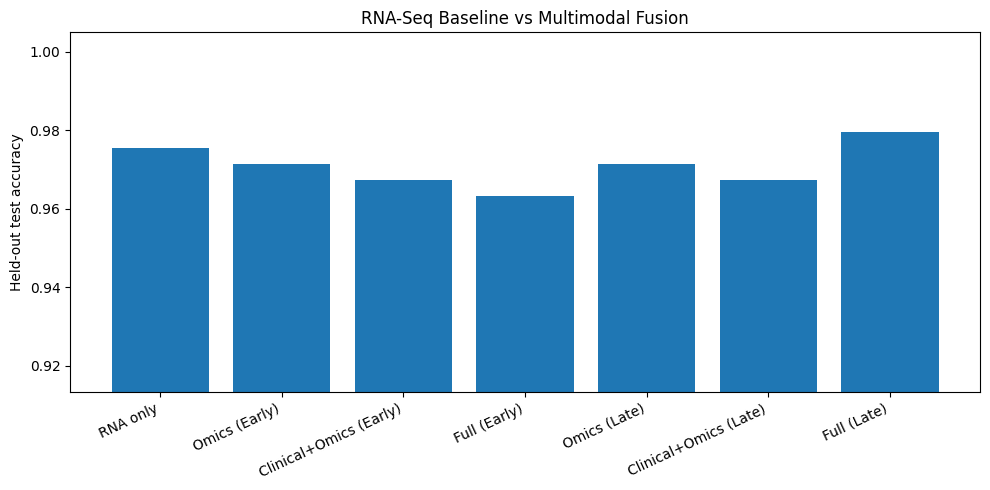

Saved: /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/Multimodal-Analysis/Matched-823-Fusion/Figures/rna_vs_multimodal_accuracy_matched_823.png


In [21]:
plot_df = rna_incremental[
    rna_incremental["budget"] == "Equal40"
].copy()

# Keep a compact set for the main figure
plot_df = plot_df[
    (
        (plot_df["strategy"] == "Unimodal")
        & (plot_df["combination"] == "RNA only")
    )
    |
    (
        (plot_df["strategy"].isin(["Early", "Late"]))
        & (plot_df["combination"].isin(["Omics", "Clinical+Omics", "Full"]))
    )
].copy()

plot_df["label"] = np.where(
    plot_df["strategy"] == "Unimodal",
    "RNA only",
    plot_df["combination"] + " (" + plot_df["strategy"] + ")"
)

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(plot_df))
ax.bar(x, plot_df["test_accuracy"])

ax.set_xticks(x)
ax.set_xticklabels(plot_df["label"], rotation=25, ha="right")
ax.set_ylabel("Held-out test accuracy")
ax.set_title("RNA-Seq Baseline vs Multimodal Fusion")

lower = max(0.0, plot_df["test_accuracy"].min() - 0.05)
ax.set_ylim(lower, 1.005)

plt.tight_layout()

FIG_PATH = FIG_DIR / "rna_vs_multimodal_accuracy_matched_823.png"
plt.savefig(FIG_PATH, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved: {FIG_PATH}")

## 22. Final consistency checks

The notebook should not be used for reporting unless every saved result confirms `n_patients = 823`.

In [22]:
checks = {
    "early_results": early_results,
    "late_results": late_results,
    "best_early": best_early,
    "best_late": best_late,
    "rna_incremental": rna_incremental,
    "ablation_summary": ablation_summary,
    "wiml_summary": wiml_summary,
}

for name, df in checks.items():
    if "n_patients" in df.columns:
        unique_n = sorted(df["n_patients"].unique().tolist())
        print(f"{name:<20}: {unique_n}")
        assert unique_n == [823]

print("\nFINAL CHECK PASSED")
print("Every reported experiment uses the same 823 patients.")
print("Outer train/test assignments are identical across experiments.")
print("Model/threshold selection uses training data only.")

early_results       : [823]
late_results        : [823]
best_early          : [823]
best_late           : [823]
rna_incremental     : [823]
ablation_summary    : [823]
wiml_summary        : [823]

FINAL CHECK PASSED
Every reported experiment uses the same 823 patients.
Outer train/test assignments are identical across experiments.
Model/threshold selection uses training data only.
